In [30]:
from config import *

In [31]:
import Minimal_Model_1D as mm1D
import Operators2D as O2d

In [3]:
def fourier_coefficients(n, sigma):
    # Generate an array of n elements sampled from a Gaussian distribution with mean 0 and variance sigma^2
    data = np.random.normal(loc=0.0, scale=np.sqrt(sigma), size=n)
    
    # Compute the Discrete Fourier Transform (DFT) of the array
    fourier_transform = np.fft.fft(data)
    
    # Return the Fourier coefficients
    return fourier_transform

# Example usage
n = 10  # Size of the array
sigma = 2.0  # Variance of the Gaussian distribution
coefficients = fourier_coefficients(n, sigma)
print("Fourier coefficients:", coefficients)

Fourier coefficients: [-6.49050594+0.j          0.27162126+4.11205073j  4.17750692+1.51008076j
  1.56103747-2.77175376j  0.61062672-3.56895267j  9.53027529+0.j
  0.61062672+3.56895267j  1.56103747+2.77175376j  4.17750692-1.51008076j
  0.27162126-4.11205073j]


In [4]:

def compute_transforms_and_multiply(n, sigma, lambda_, a):
    """
    Compute the Fourier transforms of two functions, multiply their coefficients,
    and perform an inverse Fourier transform on the result.

    Parameters:
    - n (int): Number of elements in the array.
    - sigma (float): Standard deviation of the Gaussian distribution and multiplier for the exponential function.
    - lambda_ (float): Decay constant of the exponential function.
    - a (float): Lattice spacing.

    Returns:
    - ift_result (ndarray): Result of the inverse Fourier transform of the product of the Fourier coefficients.
    """
    # First function: random Gaussian distribution
    gaussian_array = np.random.normal(loc=0, scale=np.sqrt(sigma), size=n)
    ft_gaussian = np.fft.fft(gaussian_array)
    
    # Second function: exponential decay
    j = np.arange(n)
    exponential_array = sigma * np.exp(-a * j / lambda_)
    ft_exponential = np.fft.fft(exponential_array)
    
    # Multiply the Fourier coefficients
    product_of_coefficients = ft_gaussian * ft_exponential
    
    # Perform inverse Fourier Transform on the product
    ift_result = np.fft.ifft(product_of_coefficients)
    
    return ift_result

# Example usage
n = 1024  # Number of elements
sigma = 1.0  # Variance of the Gaussian
lambda_ = 10.0  # Decay constant
a = 1.0  # Lattice spacing

ift_result = compute_transforms_and_multiply(n, sigma, lambda_, a)
print("Inverse Fourier Transform of the product:", ift_result)

Inverse Fourier Transform of the product: [-1.74531578-2.56739074e-16j -2.2668687 -1.24900090e-16j
 -1.45033877-1.06165077e-15j ... -3.09478212-1.60982339e-15j
 -2.7124017 -1.34614542e-15j -1.26026543-6.07153217e-16j]


In [16]:

def compute_transforms_and_multiply(n, sigma, lambda_, a):
    """
    Compute the Fourier transforms of two functions, multiply their coefficients,
    and perform an inverse Fourier transform on the result.

    Parameters:
    - n (int): Number of elements in the array.
    - sigma (float): Standard deviation of the Gaussian distribution and multiplier for the exponential function.
    - lambda_ (float): Decay constant of the exponential function.
    - a (float): Lattice spacing.

    Returns:
    - ift_result (ndarray): Result of the inverse Fourier transform of the product of the Fourier coefficients.
    - variance (float): Variance of the inverse Fourier transform result.
    """
    # First function: random Gaussian distribution
    gaussian_array = np.random.normal(loc=0, scale=np.sqrt(sigma), size=n)
    ft_gaussian = np.fft.fft(gaussian_array)
    
    # Second function: exponential decay
    j = np.arange(n)
    exponential_array = np.sqrt(sigma) * np.exp(-a * j / lambda_)
    ft_exponential = np.fft.fft(exponential_array)
    
    # Multiply the Fourier coefficients
    product_of_coefficients = ft_gaussian * ft_exponential
    
    # Perform inverse Fourier Transform on the product
    ift_result = np.fft.ifft(product_of_coefficients)
    
    # Calculate the variance of the resulting array
    variance = np.var(np.abs(ift_result))
    
    return ift_result, variance

# Example usage
n = 1024  # Number of elements
sigma = 1.0  # Variance of the Gaussian
lambda_ = 10.0  # Decay constant
a = 1.0  # Lattice spacing

ift_result, result_variance = compute_transforms_and_multiply(n, sigma, lambda_, a)
print("Inverse Fourier Transform of the product:", ift_result)
print("Variance of the resulting array:", result_variance)

Inverse Fourier Transform of the product: [ 0.32820108-3.15719673e-16j -0.01790657-7.35522754e-16j
  0.32094036-3.33066907e-16j ... -1.56555094-4.02455846e-16j
 -2.58546079-5.41233725e-16j -0.90567   +3.46944695e-17j]
Variance of the resulting array: 1.6648015129065357


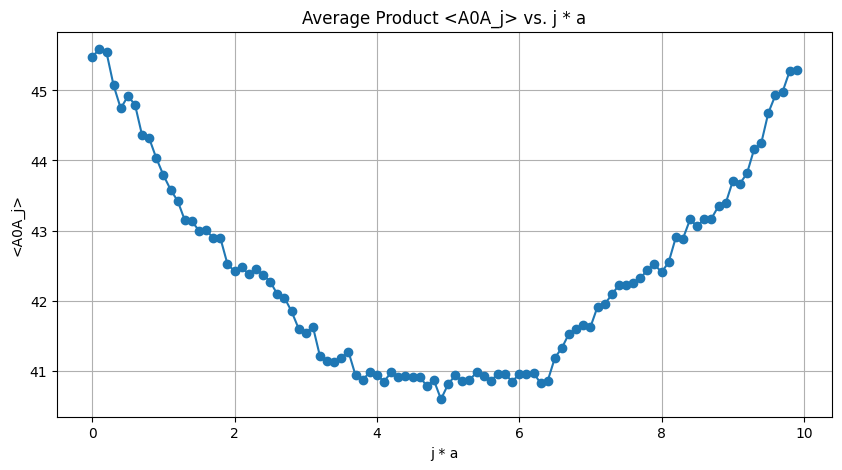

In [17]:
# Parameters
n = 100  # Array size
sigma = 1.0  # Standard deviation
lambda_ = 10.0  # Decay constant
a = 0.1  # Lattice spacing
iterations = 1000

# Initialize array to store average results
average_product = np.zeros(n)

# Run the simulation for the specified number of iterations
for _ in range(iterations):
    ift_result, _ = compute_transforms_and_multiply(n, sigma, lambda_, a)
    average_product += np.real(ift_result[0] * ift_result)

# Compute the average by dividing by the number of iterations
average_product /= iterations

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(a * np.arange(n), average_product, marker='o')
plt.xlabel('j * a')
plt.ylabel('<A0A_j>')
plt.title('Average Product <A0A_j> vs. j * a')
plt.grid(True)
plt.show()

0.00023415327146623493


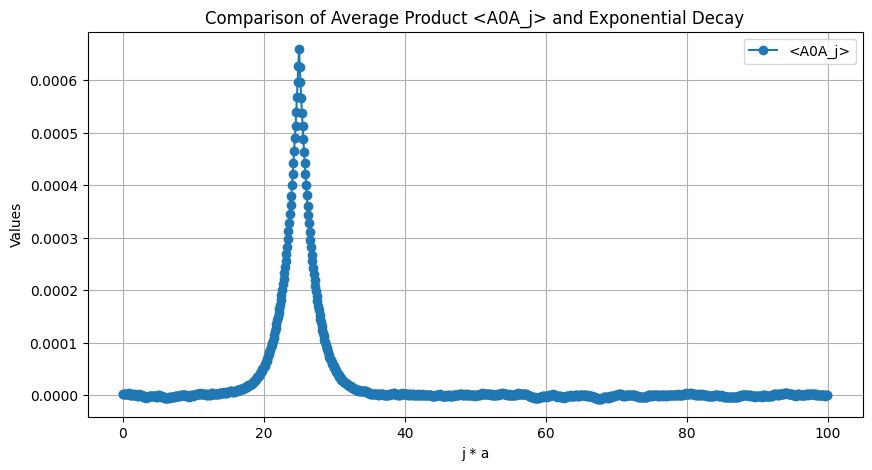

In [59]:


def compute_transforms_and_multiply(n, sigma, lambda_, a):
    gaussian_array = np.random.normal(loc=0, scale=sigma, size=n)
    ft_gaussian = np.fft.fft(gaussian_array, norm='ortho')
    j = np.arange(n) 
    exponential_array = sigma**2/2/lambda_ * np.exp(-a * np.abs(j)/ lambda_)
    ft_exponential = np.fft.fft(exponential_array, norm='ortho')
    product_of_coefficients = ft_gaussian *  np.abs(ft_exponential)
    ift_result = np.fft.ifft(product_of_coefficients,norm='ortho')
    variance = np.var(np.abs(ift_result))
    return ift_result, variance, exponential_array

# Parameters
n = 1000  # Array size
sigma = 1  # Standard deviation
lambda_ = 2.0  # Decay constant
a = 0.1  # Lattice spacing
iterations = 100000

# Initialize array to store average results
average_product = np.zeros(n)

# Initialize var_Avg store average results
var_Avg = 0 


# Store the last exponential array for plotting
last_exp_array = None

# Run the simulation for the specified number of iterations
for _ in range(iterations):
    ift_result, v, exp_array = compute_transforms_and_multiply(n, sigma, lambda_, a)
    average_product += np.real((ift_result[250] * ift_result))
    var_Avg += v
    last_exp_array = exp_array  # Store the last used exponential array

# Compute the average by dividing by the number of iterations
average_product /= iterations
var_Avg /= iterations


print(var_Avg)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(a * np.arange(n), average_product, label='<A0A_j>', marker='o')
#plt.plot(a * np.arange(n), last_exp_array, label='Exponential Decay', color='red')
plt.xlabel('j * a')
plt.ylabel('Values')
plt.title('Comparison of Average Product <A0A_j> and Exponential Decay')
plt.legend()
plt.grid(True)
plt.show()


In [58]:
np.max(average_product)/lambda_

0.000327646816639423

In [56]:
np.max(average_product)/lambda_

0.005195137920183248